## 1 · Imports & global settings

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import time

np.set_printoptions(precision=4, suppress=True)

## 2 · File paths

In [19]:
INPUT_CSV   = "input_min_conso.csv"
NEURON_CSV  = "neuron.csv"
SYN_EXC_CSV = "excitation20.csv"
SYN_INH_CSV = "inhibition20.csv"

## 3 · Hyperparameters

In [20]:
# ── Reproducibility ──────────────────────────────────────
SEED = 42

# ── Problème XOR ─────────────────────────────────────────
# Classe 1 : (x>0 ET y>0) OU (x<0 ET y<0)
# Classe 0 : (x>0 ET y<0) OU (x<0 ET y>0)
# Un seul réseau hardware, pas de Branch B ni alpha

# ── Dataset ──────────────────────────────────────────────
N_TRAIN  = 1200
N_TEST   = 400
MARGIN   = 0.05

# ── Architecture ─────────────────────────────────────────
INPUT_DIM           = 2
HIDDEN_SIZES        = [5]   # → réseau 2→8→8→2 sur Cadence

# ── Search ───────────────────────────────────────────────
N_RESTARTS = 20       # plus de restarts car pas de Branch B
MAX_PASSES = 10       # plus de passes
MARGIN_SCALE          = 5e-6
FREQ_MERGE_TOL        = 1000.0

# ── Hardware options ─────────────────────────────────────
ALLOW_ZERO_SYNAPSES            = True
ZERO_SYNAPSE_INIT_PROB         = 0.15
USE_SMALLER_WIDTHS_DEEP_LAYERS = True
DEEP_EXC_MAX                   = 1.04
DEEP_INH_MAX                   = 0.499

# ── Score ─────────────────────────────────────────────────
IMBALANCE_PENALTY_SCALE = 0.15

## 4 · Utility functions

In [21]:
def progress_bar(current, total, prefix="", suffix="", bar_len=30):
    filled = int(bar_len * current / total)
    bar    = "█" * filled + "░" * (bar_len - filled)
    pct    = int(100 * current / total)
    sys.stdout.write(f"\r  {prefix}[{bar}] {current}/{total} {pct}%  {suffix}")
    sys.stdout.flush()
    if current == total:
        sys.stdout.write("\n"); sys.stdout.flush()

## 5 · CSV readers

In [22]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if "Parameter" not in df.columns:
        raise ValueError(f"{csv_path}: missing 'Parameter' column")
    data_cols = [c for c in df.columns if c not in ["Parameter", "Unnamed: 1"]]

    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df["Parameter"] == row_name, data_cols]
        if row.empty:
            raise ValueError(f"Row '{row_name}' not found in {csv_path}")
        values = pd.to_numeric(row.iloc[0], errors="coerce").to_numpy(dtype=float)
        if (not allow_non_numeric) and np.isnan(values).any():
            raise ValueError(f"Row '{row_name}' contains non-numeric values")
        return values

    return get_row

def get_clean_rows(reader, row_names):
    rows    = [reader(name, allow_non_numeric=True) for name in row_names]
    stacked = np.vstack(rows)
    mask    = np.all(np.isfinite(stacked), axis=0)
    return [r[mask] for r in rows], mask

## 6 · Interpolation helpers

In [23]:
def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, dtype=float), xp, fp, left=fp[0], right=fp[-1])

def interp2d_bilinear_vec(x, y, x_axis, y_axis, z_grid):
    x  = np.clip(np.asarray(x, dtype=float), x_axis[0], x_axis[-1])
    y  = np.clip(np.asarray(y, dtype=float), y_axis[0], y_axis[-1])
    ix = np.clip(np.searchsorted(x_axis, x, side="right") - 1, 0, len(x_axis) - 2)
    iy = np.clip(np.searchsorted(y_axis, y, side="right") - 1, 0, len(y_axis) - 2)
    x1, x2 = x_axis[ix], x_axis[ix + 1]
    y1, y2 = y_axis[iy], y_axis[iy + 1]
    tx = np.where(x2 == x1, 0.0, (x - x1) / (x2 - x1))
    ty = np.where(y2 == y1, 0.0, (y - y1) / (y2 - y1))
    return (z_grid[ix,   iy  ] * (1-tx) * (1-ty) +
            z_grid[ix+1, iy  ] * tx     * (1-ty) +
            z_grid[ix,   iy+1] * (1-tx) * ty     +
            z_grid[ix+1, iy+1] * tx     * ty)

def strictly_monotonic_branch(x, y):
    im = int(np.argmax(y))
    x_m, y_m = np.asarray(x[:im+1], dtype=float), np.asarray(y[:im+1], dtype=float)
    order = np.argsort(x_m)
    return x_m[order], y_m[order]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, dtype=float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups], dtype=float)

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))]
                     for v in np.asarray(values, dtype=float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            vals = Y_all[mask]
            if len(vals) == 0:
                raise ValueError(f"Missing point W={w}, F={f}")
            z_grid[i, j] = np.mean(vals)
    return W_unique, F_axis, z_grid

## 7 · Load hardware tables

In [24]:
inp = read_cadence_rows(INPUT_CSV)
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(inp("Vex"), inp("Fspikes"))

neuro = read_cadence_rows(NEURON_CSV)
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(neuro("Iex"), neuro("Fspikes"))

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ["W2", "Fpre", "Ipost"])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, freq_tol=FREQ_MERGE_TOL)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ["W2", "Fpre", "Ipost"])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, freq_tol=FREQ_MERGE_TOL)

V_MIN = float(INPUT_V_AXIS[0])
V_MAX = float(INPUT_V_AXIS[-1])

print(f"Input  V : {V_MIN*1e3:.0f} mV → {V_MAX*1e3:.0f} mV")
print(f"Neuron I : {NEURON_I_AXIS[0]*1e12:.1f} pA → {NEURON_I_AXIS[-1]*1e12:.0f} pA")
print(f"Exc W ({len(W_EXC_AXIS)} valeurs µm): {W_EXC_AXIS}")
print(f"Inh W ({len(W_INH_AXIS)} valeurs µm): {W_INH_AXIS}")

Input  V : -100 mV → 100 mV
Neuron I : 3.0 pA → 1000 pA
Exc W (20 valeurs µm): [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ]
Inh W (20 valeurs µm): [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ]


## 8 · Architecture & forward pass

In [25]:
LAYER_SIZES = [INPUT_DIM] + HIDDEN_SIZES + [2]
print(f"Architecture Cadence : {LAYER_SIZES}")
print(f"Problème : XOR — classe 1 si quadrant NE ou SW, classe 0 sinon")

def input_f_of_v(Vin_V):
    return interp_clip(Vin_V, INPUT_V_AXIS, INPUT_F_AXIS)

def neuron_f_of_i(Iin_A):
    return interp_clip(Iin_A, NEURON_I_AXIS, NEURON_F_AXIS)

def get_layer_candidates(layer_idx):
    exc_axis = W_EXC_AXIS.copy()
    inh_axis = W_INH_AXIS.copy()
    if USE_SMALLER_WIDTHS_DEEP_LAYERS and layer_idx >= 1:
        exc_f = exc_axis[exc_axis <= DEEP_EXC_MAX]
        inh_f = inh_axis[inh_axis <= DEEP_INH_MAX]
        exc_axis = exc_f if len(exc_f) > 0 else W_EXC_AXIS
        inh_axis = inh_f if len(inh_f) > 0 else W_INH_AXIS
    cand = []
    if ALLOW_ZERO_SYNAPSES:
        cand.append((0, 0.0))
    cand += [(+1, float(w)) for w in exc_axis]
    cand += [(-1, float(w)) for w in inh_axis]
    return cand

ALL_CANDIDATES_PER_LAYER = [
    get_layer_candidates(l) for l in range(len(LAYER_SIZES) - 1)
]

def layer_forward_batch(Fin_batch, sign_matrix, width_matrix):
    B, N = Fin_batch.shape
    M    = sign_matrix.shape[1]
    F = np.broadcast_to(Fin_batch[:, :, None],    (B, N, M))
    W = np.broadcast_to(width_matrix[None, :, :], (B, N, M))
    S = np.broadcast_to(sign_matrix[None, :, :],  (B, N, M))
    Iexc  = interp2d_bilinear_vec(W, F, W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID)
    Iinh  = interp2d_bilinear_vec(W, F, W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID)
    Iconn = np.where(S == 1, Iexc, np.where(S == -1, -Iinh, 0.0))
    return neuron_f_of_i(np.sum(Iconn, axis=1))

def network_forward_batch(Vin_batch, sign_matrices, width_matrices):
    F = input_f_of_v(Vin_batch)
    for sm, wm in zip(sign_matrices, width_matrices):
        F = layer_forward_batch(F, sm, wm)
    return F

Architecture Cadence : [2, 5, 2]
Problème : XOR — classe 1 si quadrant NE ou SW, classe 0 sinon


## 9 · Dataset generation — XOR

In [26]:
def label_xor(X):
    x, y = X[:, 0], X[:, 1]
    same_sign = ((x > 0) & (y > 0)) | ((x < 0) & (y < 0))
    return same_sign.astype(np.int32)

def make_dataset(n, seed=0):
    rng = np.random.default_rng(seed)
    pts = []
    while sum(len(p) for p in pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n * 2, 2)).astype(np.float32)
        mask  = (np.abs(batch[:, 0]) > MARGIN) & (np.abs(batch[:, 1]) > MARGIN)
        pts.append(batch[mask])
    X = np.vstack(pts)[:n]
    return X, label_xor(X)

def xy_to_voltage(X):
    X = np.asarray(X, dtype=np.float32)
    return (V_MIN + (X + 1.0) * (V_MAX - V_MIN) / 2.0).astype(np.float32)

def make_datasets():
    X_train, y_train = make_dataset(N_TRAIN, seed=SEED)
    X_test,  y_test  = make_dataset(N_TEST,  seed=SEED + 1)
    rng = np.random.default_rng(SEED)
    idx = np.arange(len(X_train)); rng.shuffle(idx)
    X_train, y_train = X_train[idx], y_train[idx]
    V_train = xy_to_voltage(X_train)
    V_test  = xy_to_voltage(X_test)
    print(f"Train : {len(y_train)} pts | classe1={y_train.sum()} ({y_train.mean()*100:.0f}%) "
          f"classe0={(1-y_train).sum()} ({(1-y_train).mean()*100:.0f}%)")
    print(f"Test  : {len(y_test)}  pts | classe1={y_test.sum()} ({y_test.mean()*100:.0f}%) "
          f"classe0={(1-y_test).mean()*100:.0f}%)")
    return X_train, y_train, X_test, y_test, V_train, V_test

## 10 · Metrics & evaluation

In [27]:
def normalize_weights_per_class(sample_weights, y_true):
    w = np.asarray(sample_weights, dtype=float).copy()
    for cls in [0, 1]:
        mask = (np.asarray(y_true) == cls)
        if np.any(mask):
            m = np.mean(w[mask])
            if m > 0: w[mask] /= m
    return w

def weighted_mean(values, weights):
    values, weights = np.asarray(values, float), np.asarray(weights, float)
    d = np.sum(weights)
    return 0.0 if d <= 0 else float(np.sum(weights * values) / d)

def evaluate_outputs(Fout, y_true, sample_weights=None):
    y_true = np.asarray(y_true, int)
    preds  = np.argmax(Fout, axis=1)
    if sample_weights is None:
        sample_weights = np.ones(len(y_true), float)
    else:
        sample_weights = normalize_weights_per_class(sample_weights, y_true)
    mask0, mask1 = (y_true == 0), (y_true == 1)
    w0, w1 = sample_weights[mask0], sample_weights[mask1]
    acc0 = weighted_mean((preds[mask0] == 0).astype(float), w0) if np.any(mask0) else 0.0
    acc1 = weighted_mean((preds[mask1] == 1).astype(float), w1) if np.any(mask1) else 0.0
    bal_acc    = 0.5 * (acc0 + acc1)
    margin0    = weighted_mean(Fout[mask0, 0] - Fout[mask0, 1], w0) if np.any(mask0) else 0.0
    margin1    = weighted_mean(Fout[mask1, 1] - Fout[mask1, 0], w1) if np.any(mask1) else 0.0
    bal_margin = 0.5 * (margin0 + margin1)
    score = bal_acc + MARGIN_SCALE * bal_margin - IMBALANCE_PENALTY_SCALE * abs(acc0 - acc1)
    return {"preds": preds, "Fout": Fout,
            "acc0": acc0, "acc1": acc1,
            "bal_acc": bal_acc, "bal_margin": bal_margin, "score": score}

def evaluate_network(Vin, y_true, signs, widths, sample_weights=None):
    return evaluate_outputs(network_forward_batch(Vin, signs, widths), y_true, sample_weights)

def print_results(label, m):
    print(f"\n=== {label} ===")
    print(f"  acc classe 0 = {m['acc0']:.4f}  |  acc classe 1 = {m['acc1']:.4f}")
    print(f"  balanced acc = {m['bal_acc']:.4f}")
    print(f"  margin       = {m['bal_margin']*1e-3:.2f} kHz")
    print(f"  score        = {m['score']:.6f}")

## 11 · Random network & coordinate search

In [28]:
def random_network(layer_sizes, rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:])):
        if ALLOW_ZERO_SYNAPSES:
            s = rng.choice([-1, 0, 1], size=(n_in, n_out),
                           p=[(1-ZERO_SYNAPSE_INIT_PROB)/2,
                              ZERO_SYNAPSE_INIT_PROB,
                              (1-ZERO_SYNAPSE_INIT_PROB)/2])
        else:
            s = rng.choice([-1, 1], size=(n_in, n_out))
        w        = np.zeros((n_in, n_out))
        cands    = ALL_CANDIDATES_PER_LAYER[li]
        exc_only = [c[1] for c in cands if c[0] ==  1]
        inh_only = [c[1] for c in cands if c[0] == -1]
        for i in range(n_in):
            for j in range(n_out):
                if   s[i,j] ==  1: w[i,j] = rng.choice(exc_only)
                elif s[i,j] == -1: w[i,j] = rng.choice(inh_only)
        signs.append(s); widths.append(w)
    return signs, widths


def coordinate_search(V_train, y_train, V_val, y_val, layer_sizes,
                      n_restarts=N_RESTARTS, max_passes=MAX_PASSES, seed=SEED):
    rng       = np.random.default_rng(seed)
    all_conns = [(l, i, j)
                 for l, (n_in, n_out) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:]))
                 for i in range(n_in) for j in range(n_out)]
    n_conns   = len(all_conns)
    best_signs_g = best_widths_g = None
    best_val_score = best_train_score = -1e99
    best_history   = []

    for restart in range(n_restarts):
        print(f"\n{'='*60}\nRESTART {restart+1}/{n_restarts}")
        signs, widths = random_network(layer_sizes, rng)
        tr = evaluate_network(V_train, y_train, signs, widths)
        va = evaluate_network(V_val,   y_val,   signs, widths)
        history = [{"pass":0, "tr_bal_acc":tr["bal_acc"], "tr_score":tr["score"],
                    "va_bal_acc":va["bal_acc"], "va_score":va["score"]}]
        print(f"Init | tr_acc={tr['bal_acc']:.4f} score={tr['score']:.6f} | "
              f"va_acc={va['bal_acc']:.4f} score={va['score']:.6f}")
        t0 = time.time()

        for pass_idx in range(max_passes):
            improved   = False
            conn_order = list(all_conns); rng.shuffle(conn_order)

            for conn_num, (l, i, j) in enumerate(conn_order):
                # Sauvegarder l'état original
                orig_s = signs[l][i, j]
                orig_w = widths[l][i, j]
                best_s, best_w, best_c = orig_s, orig_w, tr["score"]

                # Tester tous les candidats
                for cs, cw in ALL_CANDIDATES_PER_LAYER[l]:
                    if cs == orig_s and np.isclose(cw, orig_w):
                        continue
                    signs[l][i, j]  = cs
                    widths[l][i, j] = cw
                    ctr = evaluate_network(V_train, y_train, signs, widths)
                    if ctr["score"] > best_c:
                        best_c, best_s, best_w = ctr["score"], cs, cw
                    # Restaurer à l'original
                    signs[l][i, j]  = orig_s
                    widths[l][i, j] = orig_w

                # Appliquer le meilleur
                signs[l][i, j]  = best_s
                widths[l][i, j] = best_w
                if best_c > tr["score"]:
                    tr = evaluate_network(V_train, y_train, signs, widths)
                    improved = True

                progress_bar(conn_num+1, n_conns,
                             suffix=f"pass {pass_idx+1} acc={tr['bal_acc']:.4f} {time.time()-t0:.0f}s")

            va = evaluate_network(V_val, y_val, signs, widths)
            history.append({"pass":pass_idx+1, "tr_bal_acc":tr["bal_acc"], "tr_score":tr["score"],
                             "va_bal_acc":va["bal_acc"], "va_score":va["score"]})
            print(f"Pass {pass_idx+1} | tr_acc={tr['bal_acc']:.4f} score={tr['score']:.6f} | "
                  f"va_acc={va['bal_acc']:.4f} score={va['score']:.6f}")
            if not improved: print("Converged"); break

        if (va["score"] > best_val_score or
                (np.isclose(va["score"], best_val_score) and tr["score"] > best_train_score)):
            best_signs_g     = [s.copy() for s in signs]
            best_widths_g    = [w.copy() for w in widths]
            best_val_score   = va["score"]
            best_train_score = tr["score"]
            best_history     = history
            print(f"  ★ Nouveau meilleur : val_score={best_val_score:.6f}")

    return best_signs_g, best_widths_g, best_history

## 12 · Visualisation

In [29]:
def plot_decision_map(signs, widths, X_test=None, y_test=None,
                      title="Décision réseau", resolution=120):
    xs, ys = np.linspace(-1, 1, resolution), np.linspace(-1, 1, resolution)
    XX, YY = np.meshgrid(xs, ys)
    grid_V = xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()]))
    Fout   = network_forward_batch(grid_V, signs, widths)
    pred   = np.argmax(Fout, axis=1).reshape(XX.shape)
    margin = (Fout[:,1] - Fout[:,0]).reshape(XX.shape) * 1e-3

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ax = axes[0]
    ax.contourf(XX, YY, pred, levels=[-0.5, 0.5, 1.5],
                colors=["#e06c7544", "#61afef44"])
    ax.contour(XX, YY, margin, levels=[0], colors="k", linewidths=2)
    ax.axhline(0, color="gray", lw=1, ls="--")
    ax.axvline(0, color="gray", lw=1, ls="--")
    if X_test is not None:
        ax.scatter(X_test[y_test==0,0], X_test[y_test==0,1], s=4, c="#e06c75", alpha=0.5)
        ax.scatter(X_test[y_test==1,0], X_test[y_test==1,1], s=4, c="#61afef", alpha=0.5)
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(True, alpha=0.3)

    ax = axes[1]
    vmax = max(abs(float(margin.min())), abs(float(margin.max())), 1.0)
    cf = ax.contourf(XX, YY, margin, levels=50, cmap="RdYlGn", vmin=-vmax, vmax=vmax)
    plt.colorbar(cf, ax=ax, label="F_classe1 - F_classe0 (kHz)")
    ax.contour(XX, YY, margin, levels=[0], colors="k", linewidths=2)
    ax.axhline(0, color="gray", lw=1, ls="--")
    ax.axvline(0, color="gray", lw=1, ls="--")
    ax.set_title("Marge de fréquence"); ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

def print_network(signs, widths):
    names = (["In->H1"] + [f"H{k}->H{k+1}" for k in range(1, len(signs)-1)]
             + [f"H{len(signs)-1}->Out"])
    print(f"\n=== RÉSEAU FINAL ({LAYER_SIZES}) ===")
    for k, (s, w, ln) in enumerate(zip(signs, widths, names)):
        print(f"  Layer {k+1} [{ln}] {s.shape[0]}->{s.shape[1]}"
              f"  exc={int((s==1).sum())} inh={int((s==-1).sum())} off={int((s==0).sum())}")
        print(f"    signs:\n{s}")
        print(f"    widths (µm):\n{w}")

def plot_dataset(X, y, title="Dataset XOR"):
    plt.figure(figsize=(5,5))
    plt.scatter(X[y==0,0], X[y==0,1], s=6, alpha=0.5, c="#e06c75", label="Classe 0 (NW/SE)")
    plt.scatter(X[y==1,0], X[y==1,1], s=6, alpha=0.5, c="#61afef", label="Classe 1 (NE/SW)")
    plt.axhline(0, color="k", lw=1, ls="--"); plt.axvline(0, color="k", lw=1, ls="--")
    plt.xlabel("x"); plt.ylabel("y"); plt.title(title)
    plt.gca().set_aspect("equal"); plt.legend(fontsize=8); plt.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

def plot_history(history, title="Historique recherche"):
    if not history: return
    passes = [h["pass"] for h in history]
    plt.figure(figsize=(7,4))
    plt.plot(passes, [h["tr_bal_acc"] for h in history], "o-", label="Train bal acc")
    plt.plot(passes, [h["va_bal_acc"] for h in history], "s-", label="Test bal acc")
    plt.xlabel("Pass"); plt.ylabel("Balanced accuracy"); plt.title(title)
    plt.ylim(0.4, 1.05)
    plt.axhline(0.5, color="gray", ls=":", lw=1, label="Aléatoire")
    plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

## 13 · Génération du dataset

Train : 1200 pts | classe1=619 (52%) classe0=581 (48%)
Test  : 400  pts | classe1=209 (52%) classe0=48%)


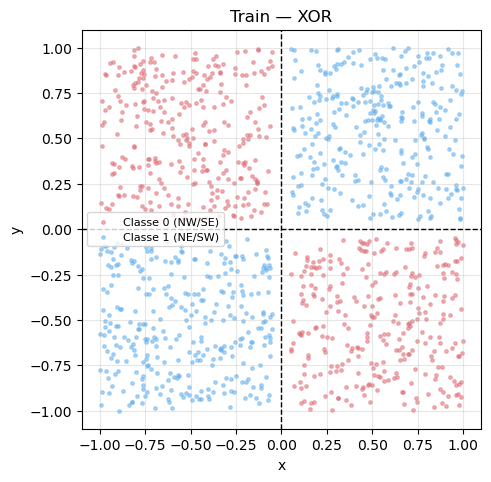

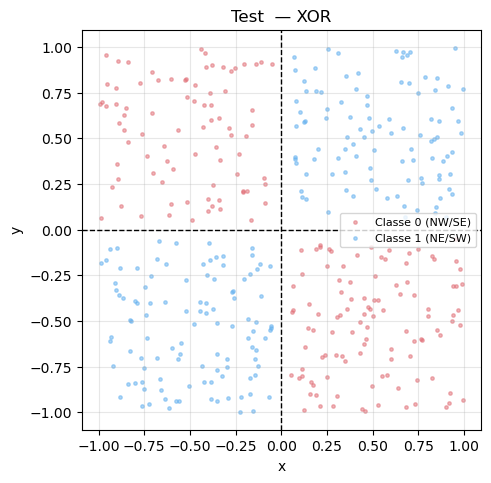

In [30]:
X_train, y_train, X_test, y_test, V_train, V_test = make_datasets()
plot_dataset(X_train, y_train, title="Train — XOR")
plot_dataset(X_test,  y_test,  title="Test  — XOR")

## 14 · Entraînement — réseau unique

In [31]:
print(f"Architecture : {LAYER_SIZES}")
print(f"Restarts : {N_RESTARTS}  |  Max passes : {MAX_PASSES}")

signs, widths, history = coordinate_search(
    V_train, y_train, V_test, y_test,
    layer_sizes=LAYER_SIZES,
    n_restarts=N_RESTARTS,
    max_passes=MAX_PASSES,
    seed=SEED
)

Architecture : [2, 5, 2]
Restarts : 20  |  Max passes : 10

RESTART 1/20
Init | tr_acc=0.5000 score=0.350579 | va_acc=0.5000 score=0.350627


  [██████████████████████████████] 20/20 100%  pass 1 acc=0.5000 1s
Pass 1 | tr_acc=0.5000 score=0.357920 | va_acc=0.5000 score=0.355997
  [██████████████████████████████] 20/20 100%  pass 2 acc=0.5000 2s
Pass 2 | tr_acc=0.5000 score=0.358160 | va_acc=0.5000 score=0.356183
  [██████████████████████████████] 20/20 100%  pass 3 acc=0.5000 3s
Pass 3 | tr_acc=0.5000 score=0.358426 | va_acc=0.5000 score=0.356317
  [██████████████████████████████] 20/20 100%  pass 4 acc=0.5000 4s
Pass 4 | tr_acc=0.5000 score=0.358472 | va_acc=0.5000 score=0.356336
  [██████████████████████████████] 20/20 100%  pass 5 acc=0.5000 5s
Pass 5 | tr_acc=0.5000 score=0.358611 | va_acc=0.5000 score=0.356429
  [██████████████████████████████] 20/20 100%  pass 6 acc=0.5000 6s
Pass 6 | tr_acc=0.5000 score=0.358736 | va_acc=0.5000 score=0.356598
  [██████████████████████████████] 20/20 100%  pass 7 acc=0.5000 7s
Pass 7 | tr_acc=0.5000 score=0.358822 | va_acc=0.5000 score=0.356657
  [██████████████████████████████] 20/20 

## 15 · Résultats


=== TRAIN ===
  acc classe 0 = 0.9862  |  acc classe 1 = 0.4992
  balanced acc = 0.7427
  margin       = 1.65 kHz
  score        = 0.677895

=== TEST ===
  acc classe 0 = 0.9895  |  acc classe 1 = 0.5120
  balanced acc = 0.7507
  margin       = 1.55 kHz
  score        = 0.686847


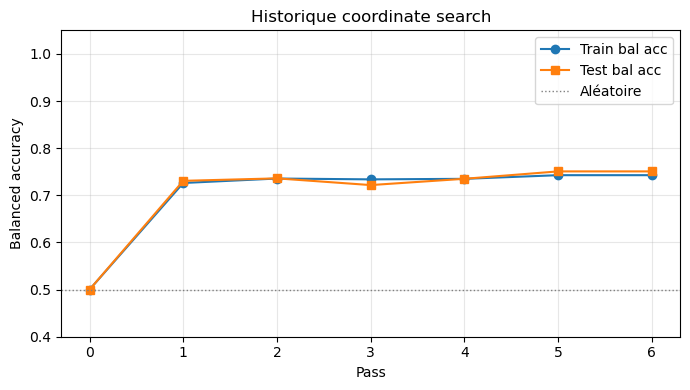

In [32]:
m_train = evaluate_network(V_train, y_train, signs, widths)
m_test  = evaluate_network(V_test,  y_test,  signs, widths)
print_results("TRAIN", m_train)
print_results("TEST",  m_test)
plot_history(history, title="Historique coordinate search")

## 16 · Carte de décision

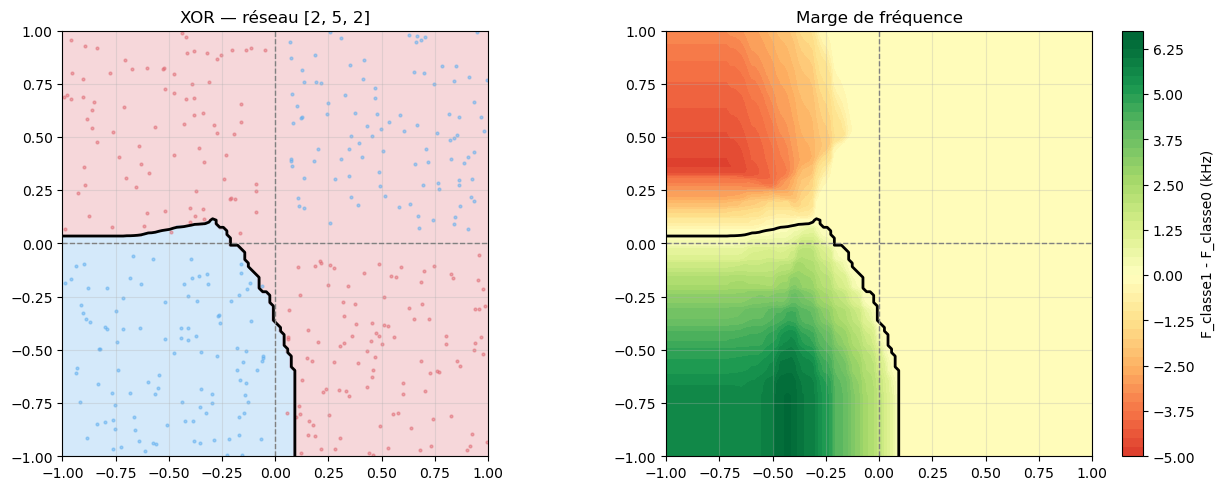

In [33]:
plot_decision_map(signs, widths, X_test=X_test, y_test=y_test,
                  title=f"XOR — réseau {LAYER_SIZES}")

## 17 · Poids pour Cadence

In [34]:
print_network(signs, widths)

# Export CSV des poids — prêt pour Cadence
rows = []
for layer_idx, (s, w) in enumerate(zip(signs, widths)):
    n_in, n_out = s.shape
    for i in range(n_in):
        for j in range(n_out):
            rows.append({
                "layer":    layer_idx + 1,
                "pre":      i,
                "post":     j,
                "sign":     int(s[i, j]),          # +1=EXC, -1=INH, 0=OFF
                "width_um": float(w[i, j]),         # largeur W en µm
                "type":     "EXC" if s[i,j]==1 else ("INH" if s[i,j]==-1 else "OFF")
            })

import pandas as pd
df_weights = pd.DataFrame(rows)
df_weights.to_csv("weights_cadence.csv", index=False)
print("\nFichier weights_cadence.csv généré :")
print(df_weights.to_string(index=False))


=== RÉSEAU FINAL ([2, 5, 2]) ===
  Layer 1 [In->H1] 2->5  exc=6 inh=2 off=2
    signs:
[[ 1  1  1  0  1]
 [ 1 -1  1  0 -1]]
    widths (µm):
[[1.643  0.2858 0.2858 0.     0.135 ]
 [0.135  0.5447 2.548  0.     0.2261]]
  Layer 2 [H1->Out] 5->2  exc=2 inh=7 off=1
    signs:
[[-1 -1]
 [-1 -1]
 [ 0 -1]
 [ 1  1]
 [-1 -1]]
    widths (µm):
[[0.1805 0.3171]
 [0.3626 0.135 ]
 [0.     0.1805]
 [0.5874 1.04  ]
 [0.1805 0.4082]]

Fichier weights_cadence.csv généré :
 layer  pre  post  sign  width_um type
     1    0     0     1    1.6430  EXC
     1    0     1     1    0.2858  EXC
     1    0     2     1    0.2858  EXC
     1    0     3     0    0.0000  OFF
     1    0     4     1    0.1350  EXC
     1    1     0     1    0.1350  EXC
     1    1     1    -1    0.5447  INH
     1    1     2     1    2.5480  EXC
     1    1     3     0    0.0000  OFF
     1    1     4    -1    0.2261  INH
     2    0     0    -1    0.1805  INH
     2    0     1    -1    0.3171  INH
     2    1     0    -1    0.362